# Предзагрузка для работы всех данных

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("model_files").resolve()))

%load_ext autoreload
%autoreload 2
import json

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from run import load_split, make_model, read_config
from tqdm.auto import tqdm

HERE = Path().resolve()
DEFAULT_CHECKPOINT = HERE / "model_files" / "checkpoint" / "best.pt"
DEFAULT_CHECKPOINT_CONFIG = HERE / "model_files" / "checkpoint" / "config.yaml"
DEFAULT_TRAIN_CONFIG = HERE / "config.json"

checkpoint = DEFAULT_CHECKPOINT
config = read_config(DEFAULT_CHECKPOINT_CONFIG)

# cборка модели
seed = config["train"]["seed"]
saved = torch.load(
    HERE / "model_files" / "checkpoint" / "best.pt", map_location="cpu", weights_only=True
)
model = make_model(
    config, json.loads((HERE / "model_files" / "data" / "metadata.json").read_text())
)
model.load_state_dict(saved["model_state"], strict=True)
device = torch.device("mps") if torch.mps.is_available() else torch.device("cpu")
model.to(device)
model.eval()  # устанавливаем в режим инфириенса и собираем градиенты.


batch = 100
split = "val"
metadata = json.loads((HERE / "model_files" / "data" / "metadata.json").read_text())
evaluation = load_split(HERE / "model_files" / "data", split, config, metadata, None)
keys = config["model"]["transaction_keys"]


batch_args = {
    "metadata": metadata,
    "keys": keys,
    "device": device,
    "batch_size": 32,
    "seed": seed,
    "shuffle": True,
}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
df = pl.scan_parquet("model_files/data/transactions.parquet").collect(engine="streaming")

Сканируем датасет и разбиваем его по клиентам, которые получили бы одобрение.

In [31]:
df_clients = df.filter(pl.col("target").eq(1)).partition_by("client_id")

Разбиваем по id в `df_clients` по размеру транзакций клиента.

In [32]:
client_amounts = []
client_amounts_len = []
for x in range(len(df_clients)):
    client_amounts += [df_clients[x]["amount"].to_torch()]
    client_amounts_len += [len(df_clients[x]["amount"])]

In [33]:
client_len_argsort = torch.argsort(torch.tensor(client_amounts_len))

В рамках исследования будем смотреть на разных клиентов по числу транзакций:
Выделим клиентов с малой информацией, с средней и с наибольшей и посмотрим на то, как это будет предсказывать IG, а также какие дополнительные данные мы можем извлечь из вкладов признаков.

In [34]:
slice_small = client_len_argsort[:50]
slice_big = client_len_argsort[-50:]
slice_medium = client_len_argsort[len(client_amounts_len) // 2 : len(client_amounts_len) // 2 + 50]

In [35]:
from xai_methods.ig import run_ig_segment

client_attrib = []

dict = {}
for slice in [slice_small, slice_medium, slice_big]:
    dict[slice] = []
    for x in tqdm(slice):
        dict[slice] += [
            run_ig_segment(
                model,
                df,
                df_clients[x]["client_id"][0],
                "amount",
                window_size=None,
                batch_args=batch_args,
                top_k_attr=None,
                IG_PRECISION=200,
                keep_per_windows_attr=True,
            )[1]
        ]

  0%|          | 0/50 [00:00<?, ?it/s]

100%|██████████| 50/50 [02:44<00:00,  3.29s/it]


In [36]:
from xai_methods.ig import score_model

dict_diff_score = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_diff_score[slice] = []
    for x in tqdm(slice):
        df_copy = df_clients[x].clone()
        df_copy = df_copy.with_columns(
            pl.Series("amount", torch.zeros(len(df_copy["amount"]))).alias("amount")
        )
        ans = [
            (
                score_model(model, df_clients[x], batch_args)
                - score_model(model, df_copy, batch_args)
            )
            .detach()
            .cpu()
        ]
        dict_diff_score[slice] += ans

100%|██████████| 50/50 [00:01<00:00, 48.99it/s]


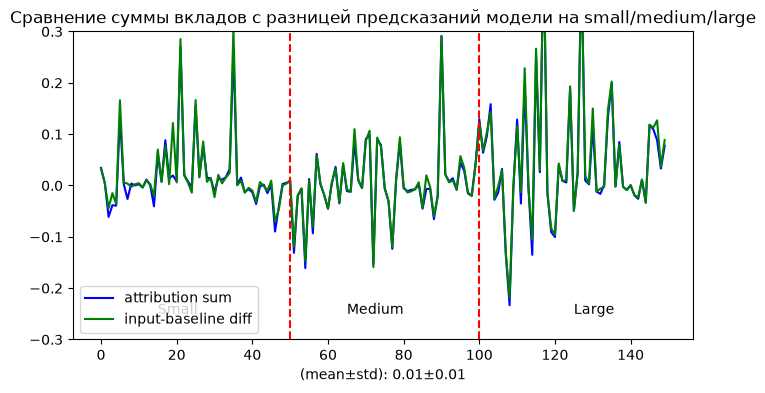

In [37]:
all_attr_sum = []
for slice in [slice_small, slice_medium, slice_big]:
    all_attr_sum += [attr.sum() for attr in dict[slice]]

all_diff_score = []
for slice in [slice_small, slice_medium, slice_big]:
    all_diff_score += [attr.sum() for attr in dict_diff_score[slice]]


plt.figure(figsize=(8, 4))
plt.plot(all_attr_sum, color="blue", label="attribution sum")
plt.plot(all_diff_score, color="green", label="input-baseline diff")
plt.axvline(50, color="red", linestyle="--")
plt.axvline(100, color="red", linestyle="--")
plt.annotate("Small", (15, -0.25))
plt.annotate("Medium", (65, -0.25))
plt.annotate(
    "Large",
    (125, -0.25),
)
plt.ylim((-0.3, 0.3))
plt.legend()
plt.title("Сравнение суммы вкладов с разницей предсказаний модели на small/medium/large")
plt.xlabel(
    f"(mean$\pm$std): {np.mean(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}$\pm${np.std(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}"
)
plt.show()

Здесь мы проверили Completness аксиому из оригинальной статьи, наш метод ей удоволетворяет.

Теперь давайте считать masked ablation score, по простому мы берем признак с наибольшим вкладом и удаляем после чего заново смотрим как отвечает модель, так мы делаем для всех признаков в порядке возрастания(убывания) и смотрим на изменение уверенности модели.
Также в качестве baseline будем использовать рандомное маскирование с фиксированным сидом для воспроизводимости - это позволит производить качественное сравнение дальнейших методов.


In [38]:
from xai_methods.ig import MaskingClient, RandomMaskingClient

dict_masking_down = {}
dict_masking_up = {}
dict_rand_delete = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_masking_up[slice] = []
    dict_rand_delete[slice] = []
    dict_masking_down[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        dict_masking_down[slice] += [
            MaskingClient(
                dict[slice][idx][0],
                model,
                df_clients[x],
                "amount",
                batch_args,
                device,
                descending=True,
            )
        ]
        dict_masking_up[slice] += [
            MaskingClient(
                dict[slice][idx][0],
                model,
                df_clients[x],
                "amount",
                batch_args,
                device,
                descending=False,
            )
        ]
        dict_rand_delete[slice] += [
            RandomMaskingClient(model, df_clients[x], "amount", batch_args, device)
        ]

100%|██████████| 50/50 [05:49<00:00,  7.00s/it]


Посчитаем auc для разных видов маскирования.

In [39]:
from sklearn.metrics import auc

auc_del_top = {}
auc_del_down = {}
auc_del_random = {}


for slice in [slice_small, slice_medium, slice_big]:
    auc_del_top[slice] = []
    auc_del_down[slice] = []
    auc_del_random[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        auc_del_top[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_masking_down[slice][idx])),
                dict_masking_down[slice][idx],
            )
        ]
        auc_del_down[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_masking_up[slice][idx])), dict_masking_up[slice][idx]
            )
        ]
        auc_del_random[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_rand_delete[slice][idx])),
                dict_rand_delete[slice][idx],
            )
        ]

100%|██████████| 50/50 [00:00<00:00, 2429.76it/s]


Здесь мы сравниваем сами методы, поэтому собираем все три подвыборки в одну группу для каждого метода.

In [40]:
auc_del_down["concat"] = []
auc_del_random["concat"] = []
auc_del_top["concat"] = []
for slice in [slice_small, slice_medium, slice_big]:
    auc_del_down["concat"] += auc_del_down[slice]
    auc_del_random["concat"] += auc_del_random[slice]
    auc_del_top["concat"] += auc_del_top[slice]

auc_del_down["concat"] = np.array(auc_del_down["concat"])
auc_del_random["concat"] = np.array(auc_del_random["concat"])
auc_del_top["concat"] = np.array(auc_del_top["concat"])

In [41]:
print(f"Top oblation deleting: {auc_del_top['concat'].mean():.2f}{auc_del_top['concat'].std():.2f}")
print(
    f"Down oblation deleting: {auc_del_down['concat'].mean():.2f}+-{auc_del_down['concat'].std():.2f}"
)
print(
    f"Random oblation deleting: {auc_del_random['concat'].mean():.2f}+-{auc_del_random['concat'].std():.2f}"
)

Top oblation deleting: 0.060.07
Down oblation deleting: 0.07+-0.09
Random oblation deleting: 0.07+-0.08


In [42]:
for slice, name in [(slice_small, "small"), (slice_medium, "medium"), (slice_big, "big")]:
    print(
        f"Top oblation deleting for {name}: {np.array(auc_del_top[slice]).mean():.2f}{np.array(auc_del_top[slice]).std():.2f}"
    )
    print(
        f"Down oblation deleting for {name}: {np.array(auc_del_down[slice]).mean():.2f}+-{np.array(auc_del_down[slice]).std():.2f}"
    )
    print(
        f"Random oblation deleting for {name}: {np.array(auc_del_random[slice]).mean():.2f}+-{np.array(auc_del_random[slice]).std():.2f}"
    )

Top oblation deleting for small: 0.050.05
Down oblation deleting for small: 0.05+-0.06
Random oblation deleting for small: 0.05+-0.06
Top oblation deleting for medium: 0.060.08
Down oblation deleting for medium: 0.07+-0.09
Random oblation deleting for medium: 0.07+-0.08
Top oblation deleting for big: 0.070.08
Down oblation deleting for big: 0.08+-0.10
Random oblation deleting for big: 0.08+-0.09


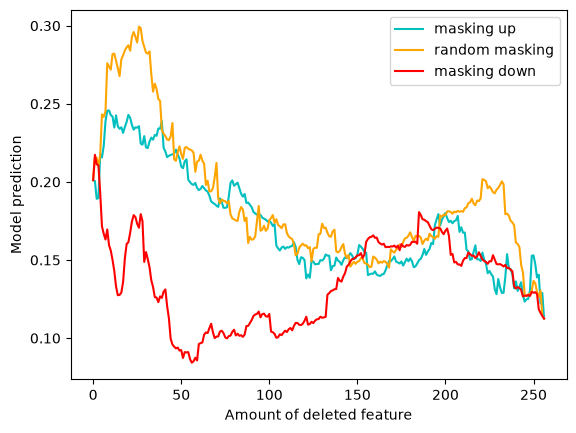

In [43]:
# ax, fig = plt.subplots()
slice = slice_big
pos = 49
plt.plot(dict_masking_up[slice][pos], color="c", label="masking up")
plt.plot(dict_rand_delete[slice][pos], color="orange", label="random masking")
plt.plot(dict_masking_down[slice][pos], color="red", label="masking down")
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.legend()
plt.show()

In [44]:
from xai_methods.ig import MaskingClientFaster

dict_masking_downf = {}
dict_masking_upf = {}
dict_rand_deletef = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_masking_upf[slice] = []
    dict_rand_deletef[slice] = []
    dict_masking_downf[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        dict_masking_downf[slice] += [
            MaskingClientFaster(
                dict[slice][idx][0],
                model,
                df_clients[x],
                "amount",
                batch_args,
                device,
                descending=True,
            )
        ]
        dict_masking_upf[slice] += [
            MaskingClientFaster(
                dict[slice][idx][0],
                model,
                df_clients[x],
                "amount",
                batch_args,
                device,
                descending=False,
            )
        ]
        dict_rand_deletef[slice] += [
            MaskingClientFaster(
                dict[slice][idx][0], model, df_clients[x], "amount", batch_args, device, random=True
            )
        ]

100%|██████████| 50/50 [00:37<00:00,  1.33it/s]


In [45]:
error_sum = 0
for slice in [slice_small, slice_medium, slice_big]:
    for idx in range(len(slice)):
        error_sum += (dict_masking_down[slice][idx] - dict_masking_downf[slice][idx]).abs().sum()
        error_sum += (dict_masking_up[slice][idx] - dict_masking_upf[slice][idx]).abs().sum()
        error_sum += (dict_rand_delete[slice][idx] - dict_rand_deletef[slice][idx]).abs().sum()
print(error_sum)

tensor(0.0006, dtype=torch.float64)


/var/folders/gb/9vxt9gqx0wg880rmldxpbwl40000gq/T/ipykernel_11232/2915906737.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  error_sum += (dict_masking_down[slice][idx] - dict_masking_downf[slice][idx]).abs().sum()
/var/folders/gb/9vxt9gqx0wg880rmldxpbwl40000gq/T/ipykernel_11232/2915906737.py:5: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  error_sum += (dict_masking_up[slice][idx] - dict_masking_upf[slice][idx]).abs().sum()
/var/folders/gb/9vxt9gqx0wg880rmldxpbwl40000gq/T/ipykernel_11232/2915906737.py:6: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  error_sum += (dict_rand_delete[slice][idx] - dict_rand_deletef[slice][idx]).abs().sum()


In [46]:
from xai_methods.timing import build_cp_from_scores

dict_cpd = {}
dict_cpp = {}
dict_cumulative_rand = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_cpd[slice] = []
    dict_cpp[slice] = []
    dict_cumulative_rand[slice] = []

    for idx, x in enumerate(slice):
        dict_cpd[slice] += [build_cp_from_scores(torch.tensor(dict_masking_downf[slice][idx]))]
        dict_cpp[slice] += [build_cp_from_scores(torch.tensor(dict_masking_upf[slice][idx]))]
        dict_cumulative_rand[slice] += [
            build_cp_from_scores(torch.tensor(dict_rand_delete[slice][idx]))
        ]

/var/folders/gb/9vxt9gqx0wg880rmldxpbwl40000gq/T/ipykernel_11232/2857193794.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dict_cumulative_rand[slice] += [build_cp_from_scores(torch.tensor(dict_rand_delete[slice][idx]))]


# Проверка более быстрого метода IG на тех же данных
### ожидаем такое же качество и график.

100%|██████████| 50/50 [00:01<00:00, 48.23it/s]


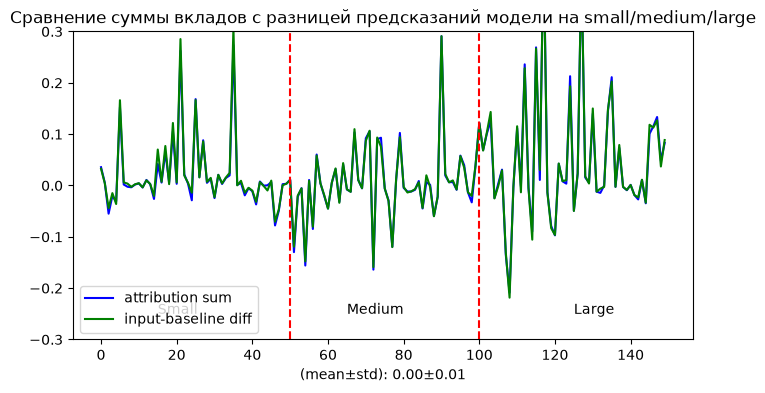

100%|██████████| 50/50 [00:00<00:00, 2597.29it/s]

Top oblation deleting: 0.060.07
Down oblation deleting: 0.07+-0.09
Random oblation deleting: 0.07+-0.08


In [47]:
from sklearn.metrics import auc

from xai_methods.ig import MaskingClientFaster, run_ig_faster, score_model

df_fast = df_clients


dict_fast = {}
batch_args["batch_size"] = 64
for slice in [slice_small, slice_medium, slice_big]:
    dfs = []
    for x in tqdm(slice):
        dfs += [df_fast[x]]
    result = run_ig_faster(
        model, dfs, "amount", window_size=None, batch_args=batch_args, IG_PRECISION=300
    )
    dict_fast[slice] = [result[df_fast[x]["client_id"][0]] for x in slice]

dict_diff_score_fast = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_diff_score_fast[slice] = []
    for x in tqdm(slice):
        df_copy = df_fast[x].clone()
        df_copy = df_copy.with_columns(
            pl.Series("amount", torch.zeros(len(df_copy["amount"]))).alias("amount")
        )
        ans = [
            (score_model(model, df_fast[x], batch_args) - score_model(model, df_copy, batch_args))
            .detach()
            .cpu()
        ]
        dict_diff_score_fast[slice] += ans

all_attr_sum = []
for slice in [slice_small, slice_medium, slice_big]:
    all_attr_sum += [attr.sum() for attr in dict_fast[slice]]

all_diff_score = []
for slice in [slice_small, slice_medium, slice_big]:
    all_diff_score += [attr.sum() for attr in dict_diff_score_fast[slice]]


plt.figure(figsize=(8, 4))
plt.plot(all_attr_sum, color="blue", label="attribution sum")
plt.plot(all_diff_score, color="green", label="input-baseline diff")
plt.axvline(50, color="red", linestyle="--")
plt.axvline(100, color="red", linestyle="--")
plt.annotate("Small", (15, -0.25))
plt.annotate("Medium", (65, -0.25))
plt.annotate(
    "Large",
    (125, -0.25),
)
plt.ylim((-0.3, 0.3))
plt.legend()
plt.title("Сравнение суммы вкладов с разницей предсказаний модели на small/medium/large")
plt.xlabel(
    f"(mean$\pm$std): {np.mean(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}$\pm${np.std(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}"
)
plt.show()

dict_masking_down_fast = {}
dict_masking_up_fast = {}
dict_rand_delete_fast = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_masking_up_fast[slice] = []
    dict_rand_delete_fast[slice] = []
    dict_masking_down_fast[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        dict_masking_down_fast[slice] += [
            MaskingClientFaster(
                dict_fast[slice][idx][0],
                model,
                df_fast[x],
                "amount",
                batch_args,
                device,
                descending=True,
            )
        ]
        dict_masking_up_fast[slice] += [
            MaskingClientFaster(
                dict_fast[slice][idx][0],
                model,
                df_fast[x],
                "amount",
                batch_args,
                device,
                descending=False,
            )
        ]
        dict_rand_delete_fast[slice] += [
            MaskingClientFaster(
                dict_fast[slice][idx][0],
                model,
                df_fast[x],
                "amount",
                batch_args,
                device,
                random=True,
            )
        ]


auc_del_top_fast = {}
auc_del_down_fast = {}
auc_del_random_fast = {}


for slice in [slice_small, slice_medium, slice_big]:
    auc_del_top_fast[slice] = []
    auc_del_down_fast[slice] = []
    auc_del_random_fast[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        auc_del_top_fast[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_masking_down_fast[slice][idx])),
                dict_masking_down_fast[slice][idx],
            )
        ]
        auc_del_down_fast[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_masking_up_fast[slice][idx])),
                dict_masking_up_fast[slice][idx],
            )
        ]
        auc_del_random_fast[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_rand_delete_fast[slice][idx])),
                dict_rand_delete_fast[slice][idx],
            )
        ]


auc_del_down_fast["concat"] = []
auc_del_random_fast["concat"] = []
auc_del_top_fast["concat"] = []
for slice in [slice_small, slice_medium, slice_big]:
    auc_del_down_fast["concat"] += auc_del_down_fast[slice]
    auc_del_random_fast["concat"] += auc_del_random_fast[slice]
    auc_del_top_fast["concat"] += auc_del_top_fast[slice]

auc_del_down_fast["concat"] = np.array(auc_del_down_fast["concat"])
auc_del_random_fast["concat"] = np.array(auc_del_random_fast["concat"])
auc_del_top_fast["concat"] = np.array(auc_del_top_fast["concat"])


print(
    f"Top oblation deleting: {auc_del_top_fast['concat'].mean():.2f}{auc_del_top_fast['concat'].std():.2f}"
)
print(
    f"Down oblation deleting: {auc_del_down_fast['concat'].mean():.2f}+-{auc_del_down_fast['concat'].std():.2f}"
)
print(
    f"Random oblation deleting: {auc_del_random_fast['concat'].mean():.2f}+-{auc_del_random_fast['concat'].std():.2f}"
)

In [48]:
for slice, name in [(slice_small, "small"), (slice_medium, "medium"), (slice_big, "big")]:
    print(
        f"Top oblation deleting for {name}: {np.array(auc_del_top_fast[slice]).mean():.2f}{np.array(auc_del_top_fast[slice]).std():.2f}"
    )
    print(
        f"Down oblation deleting for {name}: {np.array(auc_del_down_fast[slice]).mean():.2f}+-{np.array(auc_del_down_fast[slice]).std():.2f}"
    )
    print(
        f"Random oblation deleting for {name}: {np.array(auc_del_random_fast[slice]).mean():.2f}+-{np.array(auc_del_random_fast[slice]).std():.2f}"
    )

Top oblation deleting for small: 0.050.05
Down oblation deleting for small: 0.05+-0.06
Random oblation deleting for small: 0.05+-0.06
Top oblation deleting for medium: 0.060.08
Down oblation deleting for medium: 0.07+-0.09
Random oblation deleting for medium: 0.07+-0.08
Top oblation deleting for big: 0.070.08
Down oblation deleting for big: 0.08+-0.10
Random oblation deleting for big: 0.08+-0.09


In [49]:
from scipy.stats import spearmanr

ig_fast, ig = [], []
spearman_stat = []
for slice in [slice_small, slice_medium, slice_big]:
    for idx in range(len(slice)):
        rho = spearmanr(dict_fast[slice][idx].squeeze(0), dict[slice][idx].squeeze(0))
        spearman_stat += [rho.statistic]
        ig += dict[slice][idx]
        ig_fast += dict_fast[slice][idx]

ig, ig_fast = torch.concat(ig), torch.concat(ig_fast)
rho = spearmanr(ig_fast, ig)
print(
    f"Per client Spearman mean+/-std : {np.array(spearman_stat).mean():.5f}/{np.array(spearman_stat).std():.5f}"
)
print(f"Global Spearman statistic: {rho.statistic}")

Per client Spearman mean+/-std : 0.99308/0.00770
Global Spearman statistic: 0.9942987195837324


Как мы видим точность двух методов IG и IG-Faster очень близка, а значит можно заменить во всех вычислениях на IG-Faster.

При этом если мы будем оценивать ошибку между моделью и суммой вкладов признаков у нас будут расхождения из-за разного подхода к расчетам (один паралелльный батчевый, другой прямой последовательный) это дает неустранимый шум.

Поэтому чтобы оценить достоверно, насколько отличаются методы я использовал метод Спирмена для оценки сопостовимости рангов  из scipy.stats, чтобы оценить правильно ли оба метода оценивают вклад для признаков, чтобы не ошибится я проверил по каждому клиенту, а также глобально, везде коэффицент корреляции оставался около 99%, что означает правильную оценку признаков с учетом численной погрешности при вычислениях на видеокарте 

##### Анализ вкладов признаков различными методами

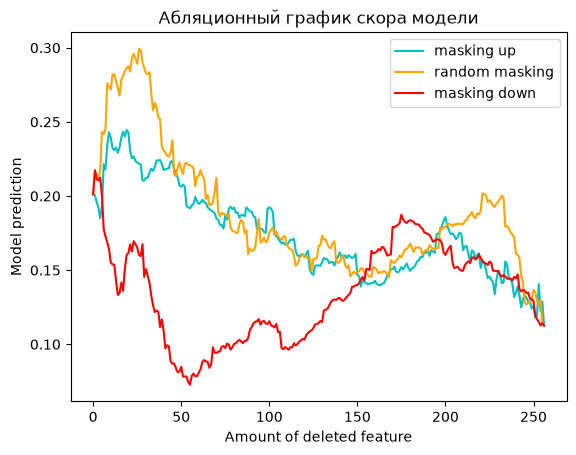

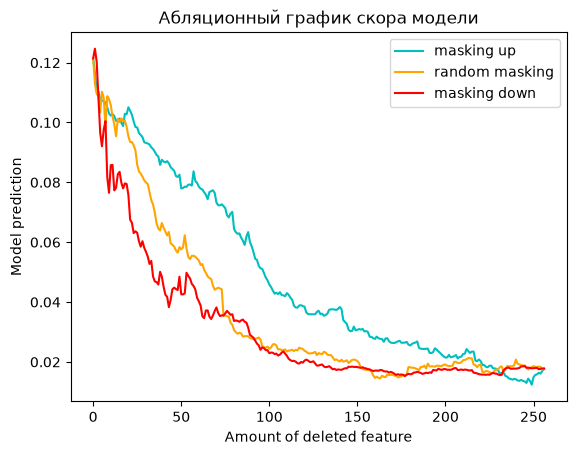

In [17]:
# ax, fig = plt.subplots()
slice = slice_big
pos = 49
plt.plot(dict_masking_up_fast[slice][pos], color="c", label="masking up")
plt.plot(dict_rand_delete_fast[slice][pos], color="orange", label="random masking")
plt.plot(dict_masking_down_fast[slice][pos], color="red", label="masking down")
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели")
plt.legend()
plt.show()


# ax, fig = plt.subplots()
slice = slice_big
pos = 2
plt.plot(dict_masking_up_fast[slice][pos], color="c", label="masking up")
plt.plot(dict_rand_delete_fast[slice][pos], color="orange", label="random masking")
plt.plot(dict_masking_down_fast[slice][pos], color="red", label="masking down")
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели")
plt.legend()
plt.show()

Мы видим, что несмотря на оценку вкладов атрибуций после удаления самых важных признаков наша модель порой не снижает скор, это скорее всего связанно с временной структурой данных либо с OOD(out-of-distribution).

Решением данной проблемы стало бы использование bert подобных архитектур для настоящего маскирования + шафлинга транзакций как на этапе обучения так и на этапе проверки - это позволило бы уменьшить влияние OOD, для оценки такого метода обычный IG уже бы не подошел но можно будет использовать GEFA метод, который гарантирует выполнение всех аксиом из оригинальных статьи, + работу с дискретными последовательностями данных.

##### Кумулитивные оценки вкладов CPP, CPD

In [15]:
from xai_methods.timing import build_cp_from_scores

dict_cpd_fast = {}
dict_cpp_fast = {}
dict_cumulative_rand_fast = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_cpd_fast[slice] = []
    dict_cpp_fast[slice] = []
    dict_cumulative_rand_fast[slice] = []

    for idx, x in enumerate(slice):
        dict_cpd_fast[slice] += [
            build_cp_from_scores(torch.tensor(dict_masking_down_fast[slice][idx]))
        ]
        dict_cpp_fast[slice] += [
            build_cp_from_scores(torch.tensor(dict_masking_up_fast[slice][idx]))
        ]
        dict_cumulative_rand_fast[slice] += [
            build_cp_from_scores(torch.tensor(dict_rand_delete_fast[slice][idx]))
        ]

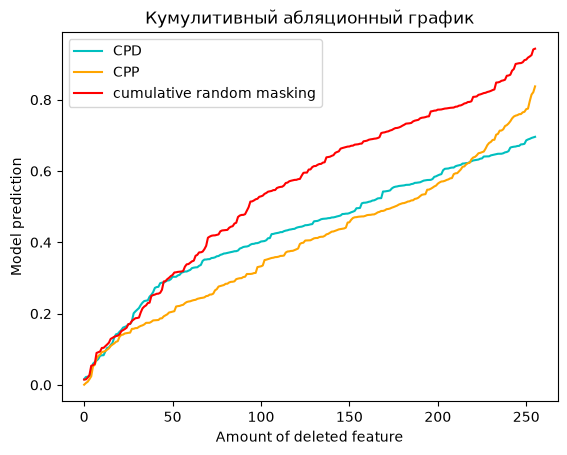

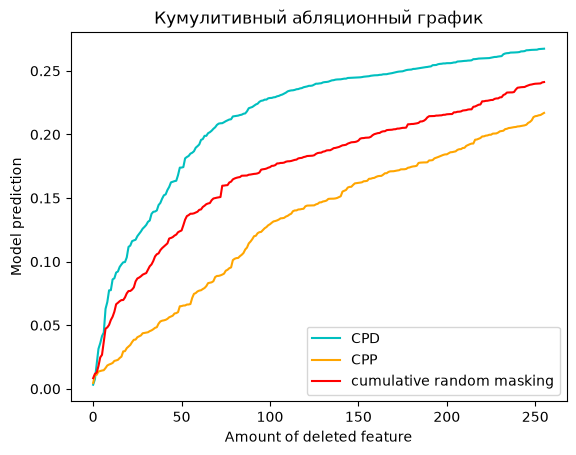

In [16]:
slice = slice_big
pos = 49
plt.plot(dict_cpd_fast[slice][pos], color="c", label="CPD")
plt.plot(dict_cpp_fast[slice][pos], color="orange", label="CPP")
plt.plot(dict_cumulative_rand_fast[slice][pos], color="red", label="cumulative random masking")
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Кумулитивный абляционный график")
plt.legend()
plt.show()

pos = 2
plt.plot(dict_cpd_fast[slice][pos], color="c", label="CPD")
plt.plot(dict_cpp_fast[slice][pos], color="orange", label="CPP")
plt.plot(dict_cumulative_rand_fast[slice][pos], color="red", label="cumulative random masking")
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Кумулитивный абляционный график")
plt.legend()
plt.show()

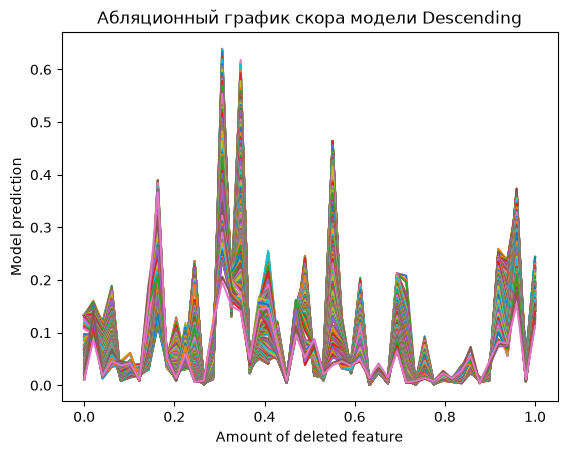

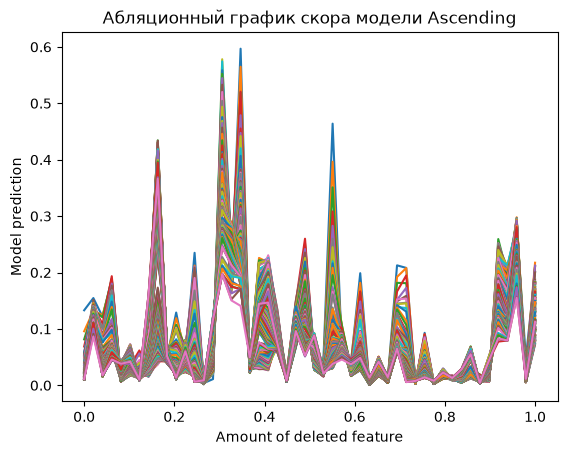

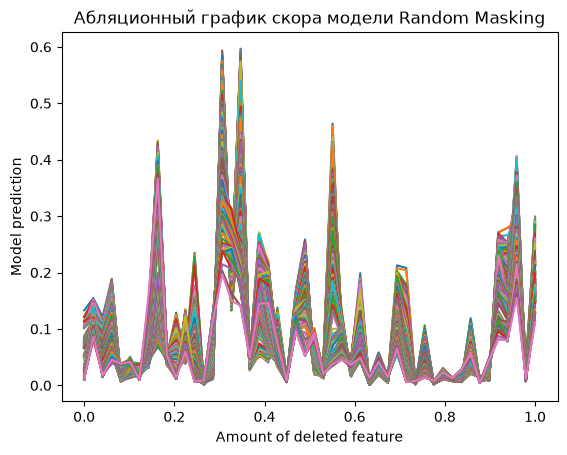

In [51]:
plt.plot(
    np.linspace(0, 1, len(dict_masking_up_fast[slice_big])),
    dict_masking_up_fast[slice_big],
    label="masking up",
)
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели Descending")
plt.show()

plt.plot(
    np.linspace(0, 1, len(dict_masking_down_fast[slice_big])),
    dict_masking_down_fast[slice_big],
    label="masking up",
)
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели Ascending")
plt.show()


plt.plot(
    np.linspace(0, 1, len(dict_masking_down_fast[slice_big])),
    dict_rand_delete_fast[slice_big],
    label="masking up",
)
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели Random Masking")
plt.show()

### Проверка для клиентов у которых `target=0`, наблюдение в маскированных абляциях.

100%|██████████| 50/50 [00:01<00:00, 46.69it/s]


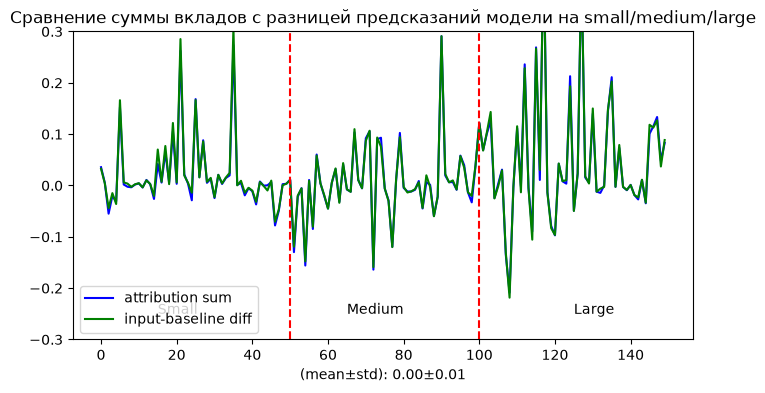

100%|██████████| 50/50 [00:37<00:00,  1.34it/s]


In [19]:
from sklearn.metrics import auc

from xai_methods.ig import MaskingClientFaster, run_ig_faster, score_model

df_zeros = df.filter(pl.col("target").eq(1)).partition_by("client_id")

client_amounts_zeros = []
client_amounts_len_zeros = []
for x in range(len(df_zeros)):
    client_amounts_zeros += [df_zeros[x]["amount"].to_torch()]
    client_amounts_len_zeros += [len(df_zeros[x]["amount"])]

client_len_argsort_zeros = torch.argsort(torch.tensor(client_amounts_len_zeros))
slice_small_zero = client_len_argsort_zeros[:50]
slice_big_zero = client_len_argsort_zeros[-50:]
slice_medium_zero = client_len_argsort_zeros[
    len(client_amounts_len) // 2 : len(client_amounts_len_zeros) // 2 + 50
]
slices_zero = [slice_small_zero, slice_medium_zero, slice_big_zero]


dict_zeros = {}
batch_args["batch_size"] = 64
for slice in slices_zero:
    dfs = []
    for x in tqdm(slice):
        dfs += [df_zeros[x]]
    result = run_ig_faster(
        model, dfs, "amount", window_size=None, batch_args=batch_args, IG_PRECISION=300
    )
    dict_zeros[slice] = [result[df_zeros[x]["client_id"][0]] for x in slice]

dict_diff_score_zeros = {}

for slice in slices_zero:
    dict_diff_score_zeros[slice] = []
    for x in tqdm(slice):
        df_copy = df_zeros[x].clone()
        df_copy = df_copy.with_columns(
            pl.Series("amount", torch.zeros(len(df_copy["amount"]))).alias("amount")
        )
        ans = [
            (score_model(model, df_zeros[x], batch_args) - score_model(model, df_copy, batch_args))
            .detach()
            .cpu()
        ]
        dict_diff_score_zeros[slice] += ans

all_attr_sum = []
for slice in slices_zero:
    all_attr_sum += [attr.sum() for attr in dict_zeros[slice]]

all_diff_score = []
for slice in slices_zero:
    all_diff_score += [attr.sum() for attr in dict_diff_score_zeros[slice]]


plt.figure(figsize=(8, 4))
plt.plot(all_attr_sum, color="blue", label="attribution sum")
plt.plot(all_diff_score, color="green", label="input-baseline diff")
plt.axvline(50, color="red", linestyle="--")
plt.axvline(100, color="red", linestyle="--")
plt.annotate("Small", (15, -0.25))
plt.annotate("Medium", (65, -0.25))
plt.annotate(
    "Large",
    (125, -0.25),
)
plt.ylim((-0.3, 0.3))
plt.legend()
plt.title("Сравнение суммы вкладов с разницей предсказаний модели на small/medium/large")
plt.xlabel(
    f"(mean$\pm$std): {np.mean(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}$\pm${np.std(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}"
)
plt.show()

dict_masking_down_zeros = {}
dict_masking_up_zeros = {}
dict_rand_delete_zeros = {}

for slice in slices_zero:
    dict_masking_up_zeros[slice] = []
    dict_rand_delete_zeros[slice] = []
    dict_masking_down_zeros[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        dict_masking_down_zeros[slice] += [
            MaskingClientFaster(
                dict_zeros[slice][idx][0],
                model,
                df_zeros[x],
                "amount",
                batch_args,
                device,
                descending=True,
            )
        ]
        dict_masking_up_zeros[slice] += [
            MaskingClientFaster(
                dict_zeros[slice][idx][0],
                model,
                df_zeros[x],
                "amount",
                batch_args,
                device,
                descending=False,
            )
        ]
        dict_rand_delete_zeros[slice] += [
            MaskingClientFaster(
                dict_zeros[slice][idx][0],
                model,
                df_zeros[x],
                "amount",
                batch_args,
                device,
                random=True,
            )
        ]

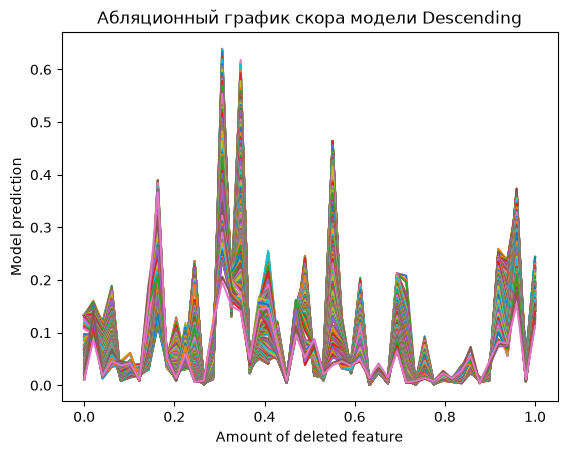

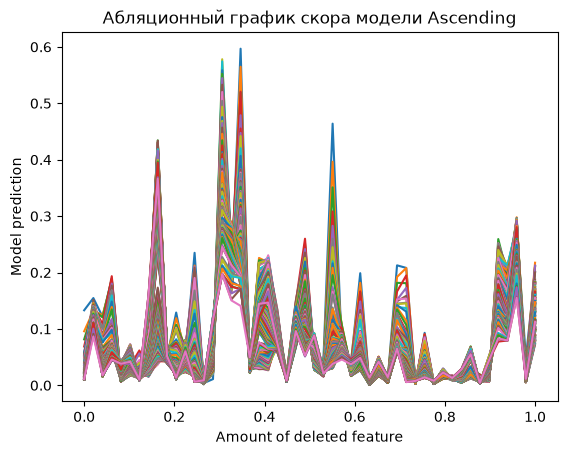

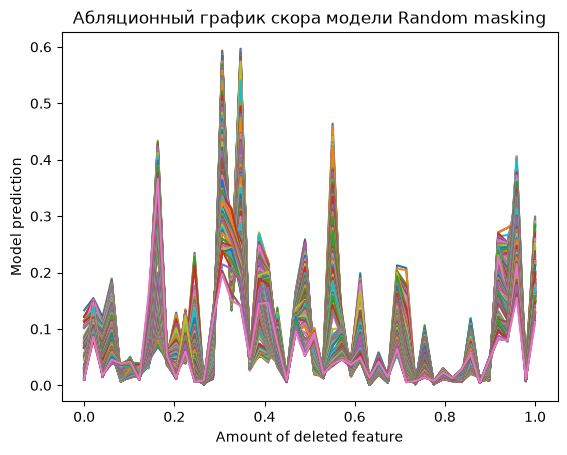

In [52]:
plt.plot(
    np.linspace(0, 1, len(dict_masking_up_zeros[slice_big_zero])),
    dict_masking_up_zeros[slice_big_zero],
    label="masking up",
)
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели Descending")
plt.show()

plt.plot(
    np.linspace(0, 1, len(dict_masking_down_zeros[slice_big_zero])),
    dict_masking_down_zeros[slice_big_zero],
    label="masking up",
)
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели Ascending")
plt.show()


plt.plot(
    np.linspace(0, 1, len(dict_masking_down_zeros[slice_big_zero])),
    dict_rand_delete_zeros[slice_big_zero],
    label="masking up",
)
plt.ylabel("Model prediction")
plt.xlabel("Amount of deleted feature")
plt.title("Абляционный график скора модели Random masking")
plt.show()

### Оконный IG и активность признаков(Coming soon)

In [62]:
# from xai_methods.ig import run_ig_faster

# df_window = df_clients

# dict_window = {}
# window_size=0.3
# batch_args['batch_size'] = 64
# for slice in [slice_small, slice_medium, slice_big]:
#     dfs = []
#     for x in tqdm(slice):
#         dfs += [df_window[x]]
#     result = run_ig_faster(model, dfs, 'amount', window_size=window_size, batch_args=batch_args, IG_PRECISION=300)
#     dict_window[slice] = [result[df_window[x]['client_id'][0]] for x in slice]

100%|██████████| 50/50 [00:00<00:00, 83618.50it/s]


: 

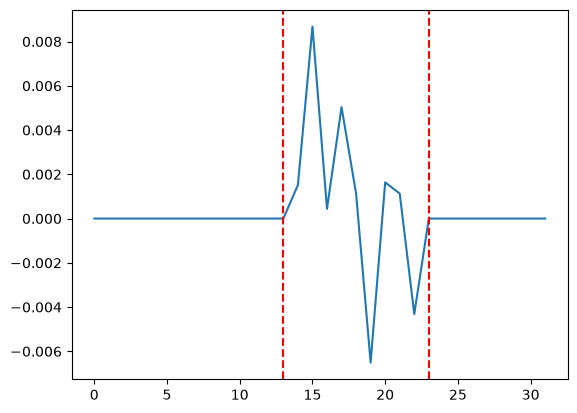

In [58]:
idx = 14
plt.plot(result[idx])
plt.axvline(idx - 1, color="r", linestyle="--")
plt.axvline(9 + idx, color="r", linestyle="--")

In [ ]:
result = result.to_torch()

# Проверка Перемешивания временных меток.
##### В силу устройства данных ожидаем, что предсказание не ухудшится

100%|██████████| 50/50 [00:01<00:00, 46.98it/s]


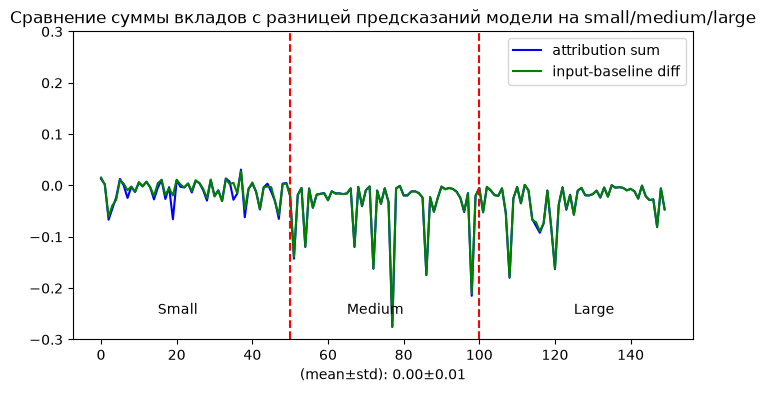

100%|██████████| 50/50 [00:00<00:00, 2632.69it/s]

Top oblation deleting: 0.020.02
Down oblation deleting: 0.01+-0.02
Random oblation deleting: 0.02+-0.02


In [448]:
from xai_methods.ig import MaskingClientFaster, run_ig_faster

df_permuted = [
    df_clients[x]
    .with_columns(pl.col("days_till_last_transaction").shuffle(seed=42))
    .sort("days_till_last_transaction", descending=True, maintain_order=True)
    for x in range(len(df_clients))
]

dict_pmt = {}
batch_args["batch_size"] = 64
for slice in [slice_small, slice_medium, slice_big]:
    dfs = []
    for x in tqdm(slice):
        dfs += [df_permuted[x]]
    result = run_ig_faster(
        model, dfs, "amount", window_size=None, batch_args=batch_args, IG_PRECISION=300
    )
    dict_pmt[slice] = [result[df_permuted[x]["client_id"][0]].to_torch() for x in slice]

dict_diff_score_pmt = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_diff_score_pmt[slice] = []
    for x in tqdm(slice):
        df_copy = df_permuted[x].clone()
        df_copy = df_copy.with_columns(
            pl.Series("amount", torch.zeros(len(df_copy["amount"]))).alias("amount")
        )
        ans = [
            (
                score_model(model, df_permuted[x], batch_args)
                - score_model(model, df_copy, batch_args)
            )
            .detach()
            .cpu()
        ]
        dict_diff_score_pmt[slice] += ans

all_attr_sum = []
for slice in [slice_small, slice_medium, slice_big]:
    all_attr_sum += [attr.sum() for attr in dict_pmt[slice]]

all_diff_score = []
for slice in [slice_small, slice_medium, slice_big]:
    all_diff_score += [attr.sum() for attr in dict_diff_score_pmt[slice]]


plt.figure(figsize=(8, 4))
plt.plot(all_attr_sum, color="blue", label="attribution sum")
plt.plot(all_diff_score, color="green", label="input-baseline diff")
plt.axvline(50, color="red", linestyle="--")
plt.axvline(100, color="red", linestyle="--")
plt.annotate("Small", (15, -0.25))
plt.annotate("Medium", (65, -0.25))
plt.annotate(
    "Large",
    (125, -0.25),
)
plt.ylim((-0.3, 0.3))
plt.legend()
plt.title("Сравнение суммы вкладов с разницей предсказаний модели на small/medium/large")
plt.xlabel(
    f"(mean$\pm$std): {np.mean(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}$\pm${np.std(np.abs(np.array(all_attr_sum) - np.array(all_diff_score))):.2f}"
)
plt.show()

dict_masking_down_permute = {}
dict_masking_up_permute = {}
dict_rand_delete_permute = {}

for slice in [slice_small, slice_medium, slice_big]:
    dict_masking_up_permute[slice] = []
    dict_rand_delete_permute[slice] = []
    dict_masking_down_permute[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        dict_masking_down_permute[slice] += [
            MaskingClientFaster(
                dict_pmt[slice][idx][0],
                model,
                df_permuted[x],
                "amount",
                batch_args,
                device,
                descending=True,
            )
        ]
        dict_masking_up_permute[slice] += [
            MaskingClientFaster(
                dict_pmt[slice][idx][0],
                model,
                df_permuted[x],
                "amount",
                batch_args,
                device,
                descending=False,
            )
        ]
        dict_rand_delete_permute[slice] += [
            MaskingClientFaster(
                dict_pmt[slice][idx][0],
                model,
                df_permuted[x],
                "amount",
                batch_args,
                device,
                random=True,
            )
        ]


auc_del_top_pmt = {}
auc_del_down_pmt = {}
auc_del_random_pmt = {}


for slice in [slice_small, slice_medium, slice_big]:
    auc_del_top_pmt[slice] = []
    auc_del_down_pmt[slice] = []
    auc_del_random_pmt[slice] = []
    pbar = enumerate(tqdm(slice))
    for idx, x in pbar:
        auc_del_top_pmt[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_masking_down_permute[slice][idx])),
                dict_masking_down_permute[slice][idx],
            )
        ]
        auc_del_down_pmt[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_masking_up_permute[slice][idx])),
                dict_masking_up_permute[slice][idx],
            )
        ]
        auc_del_random_pmt[slice] += [
            auc(
                np.linspace(0, 1, num=len(dict_rand_delete_permute[slice][idx])),
                dict_rand_delete_permute[slice][idx],
            )
        ]


auc_del_down_pmt["concat"] = []
auc_del_random_pmt["concat"] = []
auc_del_top_pmt["concat"] = []
for slice in [slice_small, slice_medium, slice_big]:
    auc_del_down_pmt["concat"] += auc_del_down_pmt[slice]
    auc_del_random_pmt["concat"] += auc_del_random_pmt[slice]
    auc_del_top_pmt["concat"] += auc_del_top_pmt[slice]

auc_del_down_pmt["concat"] = np.array(auc_del_down_pmt["concat"])
auc_del_random_pmt["concat"] = np.array(auc_del_random_pmt["concat"])
auc_del_top_pmt["concat"] = np.array(auc_del_top_pmt["concat"])


print(
    f"Top oblation deleting: {auc_del_top_pmt['concat'].mean():.2f}{auc_del_top_pmt['concat'].std():.2f}"
)
print(
    f"Down oblation deleting: {auc_del_down_pmt['concat'].mean():.2f}+-{auc_del_down_pmt['concat'].std():.2f}"
)
print(
    f"Random oblation deleting: {auc_del_random_pmt['concat'].mean():.2f}+-{auc_del_random_pmt['concat'].std():.2f}"
)

Мы видим проблему связанную с привязкой модели к временному типу данных, то есть при разных последовательностях клиентских транзакций мы по разному оцениваем риск игнорируя объемы и типы сделок за последний период, это говорит о плохом качестве тренировки модели.

###### Здесь мне пришлось залезть в исходный код модели и поменять метод создания последовательностей транзакции, и установить метод сортировки по временному признаку на stable в data.py:76 это позволило получить сопоставимые результаты между суммой вкладов и разностью скоров модели.